## Training a convnet from scratch on a small dataset

### Downloading the data

In [1]:
!unzip -qq ./shapes.zip


In [1]:
import os
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.utils import image_dataset_from_directory

base_dir = "shapes_data/shapes"

train_dir = os.path.join(base_dir, "train")
validation_dir = os.path.join(base_dir, "validation")
test_dir = os.path.join(base_dir, "test")

batch_size = 32
img_height = 180
img_width = 180

train_dataset = image_dataset_from_directory(
    train_dir,
    image_size=(180, 180),
    batch_size=32,
    label_mode="int")
validation_dataset = image_dataset_from_directory(
    validation_dir,
    image_size=(180, 180),
    batch_size=32,
    label_mode="int")
test_dataset = image_dataset_from_directory(
    test_dir,
    image_size=(180, 180),
    batch_size=32,
    label_mode="int")


class_names = train_dataset.class_names
num_classes = len(class_names)
print(f"Detected shape classes ({num_classes}): {class_names}")

data_augmentation = keras.Sequential(
    [
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.1),
        layers.RandomZoom(0.1),
    ]
)

def augment(image, label):
    return data_augmentation(image, training=True), label


train_dataset = train_dataset.map(augment, num_parallel_calls=tf.data.AUTOTUNE)

AUTOTUNE = tf.data.AUTOTUNE
train_dataset = train_dataset.shuffle(buffer_size=1000).prefetch(buffer_size=AUTOTUNE)
validation_dataset = validation_dataset.cache().prefetch(buffer_size=AUTOTUNE)

Found 4000 files belonging to 4 classes.
Found 2000 files belonging to 4 classes.
Found 4000 files belonging to 4 classes.
Detected shape classes (4): ['3', '4', '5', '6']


**Instantiating a small convnet for dogs vs. cats classification**

### Building the model

In [2]:
model = keras.Sequential([
    keras.Input(shape=(180, 180, 3)),
    layers.Rescaling(1./255),

    layers.Conv2D(filters=32, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),

    layers.Conv2D(filters=64, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),

    layers.Conv2D(filters=128, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),

    layers.Conv2D(filters=256, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),

    layers.Conv2D(filters=256, kernel_size=3, activation="relu"),

    layers.Conv2D(filters=256, kernel_size=3, activation="relu"),

    layers.Flatten(),
    layers.Dropout(0.5),
    layers.Dense(num_classes, activation="softmax")
])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 178, 178, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 89, 89, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 87, 87, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 43, 43, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 41, 41, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 18, 18, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 9, 9, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 7, 7, 256)      │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 5, 5, 256)      │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6400)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 6400)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │        25,604 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,594,180 (6.08 MB)

 Trainable params: 1,594,180 (6.08 MB)

 Non-trainable params: 0 (0.00 B)

**Configuring the model for training**

In [3]:
from tensorflow.keras.callbacks import EarlyStopping

model.compile(loss="sparse_categorical_crossentropy",
              optimizer=keras.optimizers.Adam(learning_rate=1e-4),
              metrics=["accuracy"])

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=7,
    restore_best_weights=True
)

epochs = 50
history = model.fit(
    train_dataset,
    epochs=epochs,
    validation_data=validation_dataset,
    callbacks=[early_stopping]
)

Epoch 1/50
125/125 ━━━━━━━━━━━━━━━━━━━━ 55s 123ms/step - accuracy: 0.2620 - loss: 1.3847 - val_accuracy: 0.3085 - val_loss: 1.3761
Epoch 2/50
125/125 ━━━━━━━━━━━━━━━━━━━━ 28s 45ms/step - accuracy: 0.3128 - loss: 1.3552 - val_accuracy: 0.3585 - val_loss: 1.2947
Epoch 3/50
125/125 ━━━━━━━━━━━━━━━━━━━━ 28s 45ms/step - accuracy: 0.3683 - loss: 1.2933 - val_accuracy: 0.3920 - val_loss: 1.2404
Epoch 4/50
125/125 ━━━━━━━━━━━━━━━━━━━━ 29s 47ms/step - accuracy: 0.3913 - loss: 1.2558 - val_accuracy: 0.4285 - val_loss: 1.1974
Epoch 5/50
125/125 ━━━━━━━━━━━━━━━━━━━━ 40s 46ms/step - accuracy: 0.4162 - loss: 1.2272 - val_accuracy: 0.4400 - val_loss: 1.1678
Epoch 6/50
125/125 ━━━━━━━━━━━━━━━━━━━━ 41s 46ms/step - accuracy: 0.4175 - loss: 1.2035 - val_accuracy: 0.4570 - val_loss: 1.1447
Epoch 7/50
125/125 ━━━━━━━━━━━━━━━━━━━━ 28s 46ms/step - accuracy: 0.4372 - loss: 1.1793 - val_accuracy: 0.4730 - val_loss: 1.1117
Epoch 8/50
125/125 ━━━━━━━━━━━━━━━━━━━━ 28s 45ms/step - accuracy: 0.4633 - loss: 1.1400 -

In [4]:
# Evaluate the model on the test set
test_loss, test_accuracy = model.evaluate(test_dataset)

print(f"\n--- Test Results ---")
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

125/125 ━━━━━━━━━━━━━━━━━━━━ 3s 26ms/step - accuracy: 0.9843 - loss: 0.0455

--- Test Results ---
Test Loss: 0.0455
Test Accuracy: 98.43%


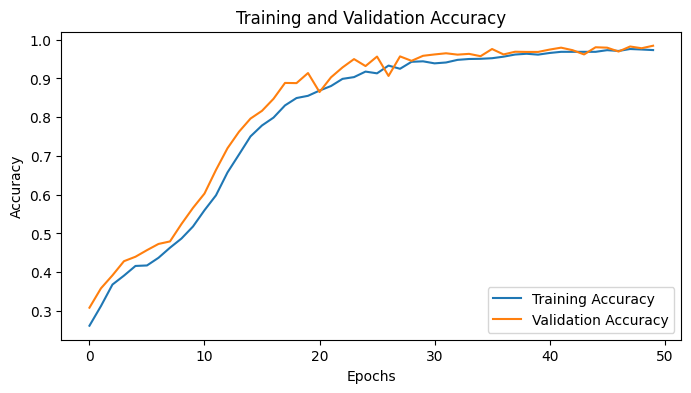

In [5]:
import matplotlib.pyplot as plt

acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']

epochs_range = range(len(acc))

plt.figure(figsize=(8, 4))
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.show()